# QL18 corridor: study area

Narrow the study area from the whole delta to the communes along **Quốc lộ 18**.
Steps:

1. Fetch OSM roads for the provinces QL18 crosses.
2. Pick out QL18 and check the fetch didn't cut it short.
3. Buffer it, choose the buffer distance, and keep the communes the buffer touches.
4. Save them as the AOI for ribbon detection.

**Which road counts as QL18.** OSM signs two roads with QL18:
- **The old national road** (`tier == 'national'`, e.g. `ref` "QL.18", named
  Quốc lộ 18 / Đường Trần Hưng Đạo / Cầu Phả Lại). Houses can front it, so this is
  where ribbons can grow. **It defines the corridor.**
- **Expressway sections co-signed QL18** (`ref` "CT.01;QL.1;QL.18"). They are
  access-controlled, so no frontage is possible. They're plotted for context only.

**Extent.** QL18 starts at Nội Bài (Sóc Sơn, Hà Nội), runs through Bắc Ninh,
crosses into Chí Linh (Hải Dương), then leaves the 9-province AOI into Quảng Ninh,
where it continues for most of its length. Only the in-AOI segment is covered here.

In [1]:
import geopandas as gpd
import pandas as pd

from desakota.crs import CRS_UTM
from desakota.highways import add_route_tier, compute_is_on_route, load_highways
from desakota.paths import DataLayout

layout = DataLayout.from_env().ensure()

communes = gpd.read_file(layout.processed / 'communes_built_frac.gpkg')
assert communes.crs == CRS_UTM
len(communes)

2136

## 1. Load roads where QL18 runs

Roads come from the Geofabrik Vietnam extract (OSM data as of 2026-10-16, see
`raw/osm/geofabrik_vietnam-261016.json`): the public Overpass endpoint no longer
serves scripted clients. Only Bắc Ninh, Hải Dương and Sóc Sơn are read; all of
Hà Nội would add many inner-city primaries that QL18 never touches. Section 2
checks this choice instead of trusting it.

In [2]:
seed_communes = communes[
    communes['province_name'].isin(['BắcNinh', 'HảiDương'])
    | (communes['district_name'] == 'SócSơn')
]
osm_extract_path = layout.raw / 'osm' / 'geofabrik_vietnam-261016' / 'vietnam.gpkg'
highways = add_route_tier(load_highways(osm_extract_path, seed_communes))
highways['length_km'] = highways.length / 1000  # carriageway-km, see README caveats
len(seed_communes), len(highways)

(417, 1856)

## 2. Pick out QL18

`compute_is_on_route` checks *every* route number on a way (`route` keeps only the
first, so "QL.17;QL.18" would be missed), then the tier splits the old road from
the expressway.

In [3]:
is_on_ql18 = compute_is_on_route(highways, 'QL18')
ql18_ways = highways[is_on_ql18 & (highways['tier'] == 'national')]
ql18_expressway_ways = highways[is_on_ql18 & (highways['tier'] == 'expressway')]

highways[is_on_ql18].groupby(['tier', 'highway'])['length_km'].agg(['count', 'sum']).round(1)

count   sum
tier       highway              
expressway motorway    101  71.1
national   motorway      3   0.5
           primary      13   4.7
           trunk       153  64.9

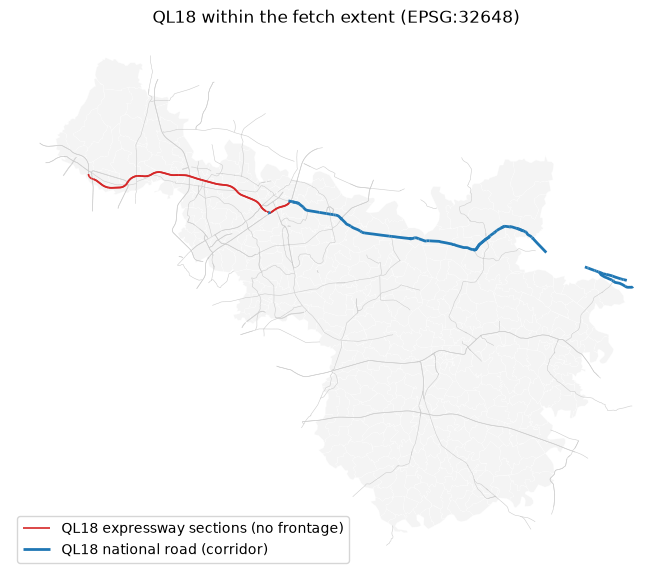

In [4]:
ax = seed_communes.plot(color='#f4f4f4', edgecolor='white', linewidth=0.2, figsize=(9, 7))
highways.plot(ax=ax, color='#cccccc', linewidth=0.4)
ql18_expressway_ways.plot(
    ax=ax, color='#d62728', linewidth=1.2, label='QL18 expressway sections (no frontage)'
)
ql18_ways.plot(ax=ax, color='#1f77b4', linewidth=2.0, label='QL18 national road (corridor)')
ax.legend(loc='lower left')
ax.set_title('QL18 within the fetch extent (EPSG:32648)')
ax.set_axis_off()

**Was QL18 cut off by the fetch extent?** Take the part of QL18 lying outside
the seed communes. If any of it falls inside *another* AOI commune, the route
continues somewhere we didn't fetch, so the extent should be widened. If it falls
only outside the AOI (Quảng Ninh, Bắc Giang), that's just the AOI edge.

This uses the old road only. The co-signed expressway sections are allowed to
continue: they run toward Hà Nội on CT.01, an expressway, which isn't part of
QL18's frontage.

In [5]:
ql18_line = ql18_ways.union_all()  # one MultiLineString; dissolves paired one-way carriageways
outside_seed = ql18_line.difference(seed_communes.union_all())
other_aoi_communes = communes.drop(seed_communes.index)
leak_length_m = other_aoi_communes.intersection(outside_seed).length
leaks_into = other_aoi_communes[leak_length_m > 50]  # ignore slivers along shared boundaries

print(f'QL18 old road outside the seed communes: {outside_seed.length / 1000:.1f} km')
print('...of which inside other AOI communes (needs a wider fetch):', len(leaks_into))
leaks_into[['province_name', 'district_name', 'commune_name']]

QL18 old road outside the seed communes: 17.4 km
...of which inside other AOI communes (needs a wider fetch): 0


,province_name,district_name,commune_name


## 3. Corridor: how wide?

A commune joins the AOI if it lies within `corridor_buffer_m` of the old road. The
table shows how the AOI grows with the buffer. Keep three scales in mind:
- **Ribbons:** about 25–100 m from the road edge.
- **Commune:** about 2.4 km across (median).
- **Comparison:** testing whether ribbon density falls off with distance needs
  communes well away from the road, not only the ones it crosses.

In [6]:
ql18_dist_m = communes.distance(ql18_line)  # 0 for communes QL18 passes through

pd.DataFrame(
    [
        {
            'corridor_buffer_m': buffer_m,
            'n_communes': int((ql18_dist_m <= buffer_m).sum()),
            'area_km2': round(communes.loc[ql18_dist_m <= buffer_m].area.sum() / 1e6),
        }
        for buffer_m in (0, 500, 1_000, 2_000, 3_000, 5_000)
    ]
)

,corridor_buffer_m,n_communes,area_km2
0,0,20,199
1,500,24,235
2,1000,33,295
3,2000,51,424
4,3000,66,555
5,5000,92,779


In [7]:
corridor_buffer_m = 2_000

corridor = ql18_line.buffer(corridor_buffer_m)
corridor_communes = communes[ql18_dist_m <= corridor_buffer_m].assign(
    dist_to_ql18_m=ql18_dist_m[ql18_dist_m <= corridor_buffer_m].round(1),
    is_crossed_by_ql18=lambda frame: frame['dist_to_ql18_m'] == 0,
)
corridor_communes['is_crossed_by_ql18'].value_counts()

is_crossed_by_ql18
False    31
True     20
Name: count, dtype: int64

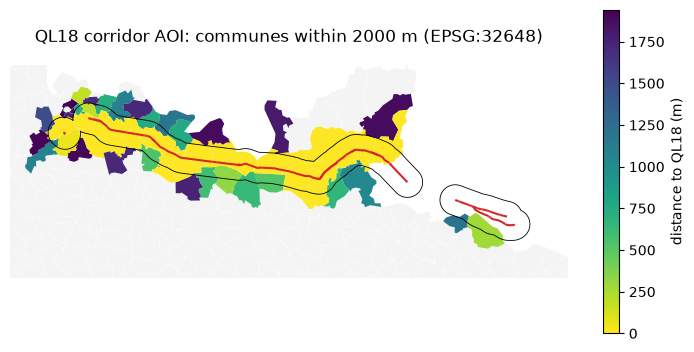

In [8]:
ax = communes.plot(color='#f4f4f4', edgecolor='white', linewidth=0.2, figsize=(9, 7))
corridor_communes.plot(
    ax=ax,
    column='dist_to_ql18_m',
    cmap='viridis_r',
    legend=True,
    legend_kwds={'label': 'distance to QL18 (m)', 'shrink': 0.6},
)
gpd.GeoSeries([corridor], crs=CRS_UTM).boundary.plot(ax=ax, color='black', linewidth=0.6)
ql18_ways.plot(ax=ax, color='#d62728', linewidth=1.5)
minx, miny, maxx, maxy = corridor.bounds
ax.set_xlim(minx - 5_000, maxx + 5_000)
ax.set_ylim(miny - 5_000, maxy + 5_000)
ax.set_title(f'QL18 corridor AOI: communes within {corridor_buffer_m} m (EPSG:32648)')
ax.set_axis_off()

Interactive version: hover to find a commune, for example your own.

In [9]:
corridor_communes.explore(
    column='dist_to_ql18_m',
    cmap='viridis_r',
    tooltip=['province_name', 'district_name', 'commune_name', 'dist_to_ql18_m', 'built_frac'],
)

## 4. Save the AOI

In [10]:
stem = 'communes_ql18_corridor'
corridor_communes.to_file(layout.processed / f'{stem}.gpkg', layer=stem, driver='GPKG')
stem, len(corridor_communes), corridor_communes.crs.to_string()

('communes_ql18_corridor', 51, 'EPSG:32648')